# Khipus.ai
## Neural Network from Scratch
### Assignment 3: Diabetes prediction - Create a neural network with PyTorch
### Name: Gabriel Severiche
<span>© Copyright Notice 2025, Khipus.ai - All Rights Reserved.</span>
---
This notebook implements a neural network using PyTorch to predict whether an individual is likely to develop diabetes. We will cover data loading, preprocessing, model definition, training, and evaluation.

### About Dataset

The Diabetes prediction dataset is a collection of medical and demographic data from patients, along with their diabetes status (positive or negative). The data includes features such as age, gender, body mass index (BMI), hypertension, heart disease, smoking history, HbA1c level, and blood glucose level. This dataset can be used to build machine learning models to predict diabetes in patients based on their medical history and demographic information. This can be useful for healthcare professionals in identifying patients who may be at risk of developing diabetes and in developing personalized treatment plans. Additionally, the dataset can be used by researchers to explore the relationships between various medical and demographic factors and the likelihood of developing diabetes.

https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset

## 1. Importing Required Libraries
We start by importing the necessary libraries for data manipulation, visualization, and building our neural network.

In [24]:
# Import NumPy for numerical operations and array handling
# Import pandas for data manipulation and analysis
# Import PyTorch for building and training neural networks
# Import the neural network module from PyTorch
# Import optimization algorithms from PyTorch
# Import function to split data into training and test sets
# Import scaler to standardize features
# Import matplotlib for plotting and visualization
# Import seaborn for advanced data visualization
# Import metrics for model evaluation

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score


## 2. Loading the Dataset
We will load the diabetes_prediction_dataset.csv file and display the first few rows to understand its structure.

In [25]:
# Load the dataset from a CSV file using pandas
# Read the diabetes prediction dataset into a pandas DataFrame
data = pd.read_csv('diabetes_prediction_dataset.csv')

# Display the first five rows of the DataFrame to inspect the data structure
data.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 3. Data Preprocessing

In [26]:
# Encode categorical features and handle missing values
# Map 'Male' to 1, 'Female' to 0, and fill missing values with 0 for the 'gender' column
data['gender'] = data['gender'].map({'Male': 1, 'Female': 0}).fillna(0)

# Map smoking history categories to integers and fill missing values with 0
data['smoking_history'] = data['smoking_history'].map({'never': 0, 'former': 3, 'current': 2, 'No info': 1}).fillna(0)

We will separate the features and labels, split the dataset into training and testing sets, and scale the features.

In [27]:
# Separate features and labels

# Features - Remove the 'diabetes' column from the dataframe and convert remaining columns into a numpy array containing all feature data.
X = data.drop('diabetes', axis=1).values

# Labels - Extract the 'diabetes' column from the dataframe as a numpy array containing the target values.
y = data['diabetes'].values

# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Partition the feature array (X) and label array (y) into training and test sets. test_size=0.2 means 20% of the data will be used for testing, while 80% is reserved for training. random_state=42 ensures reproducibility of the split.

# Scale the features
# Initialize the StandardScaler object to standardize features by removing the mean and scaling to unit variance.
scaler = StandardScaler()

# Fit the scaler on the training feature data (compute mean and standard deviation) and transform the training data accordingly.
# Convert the categorical columns in both splits to numbers before scaling
feature_cols = data.drop(columns=['diabetes']).columns

X_train_df = pd.DataFrame(X_train, columns=feature_cols)
X_test_df = pd.DataFrame(X_test, columns=feature_cols)

gender_map = {'Male': 1, 'Female': 0}
smoking_map = {'never': 0, 'former': 3, 'current': 2, 'No Info': 1}

X_train_df['gender'] = X_train_df['gender'].map(gender_map).fillna(0)
X_train_df['smoking_history'] = X_train_df['smoking_history'].map(smoking_map).fillna(0)

X_test_df['gender'] = X_test_df['gender'].map(gender_map).fillna(0)
X_test_df['smoking_history'] = X_test_df['smoking_history'].map(smoking_map).fillna(0)

# Fit scaler on training data and transform both train/test splits
X_train = scaler.fit_transform(X_train_df.astype(float))
X_test = scaler.transform(X_test_df.astype(float))

# Apply the transformation to the test data using the statistics computed from the training data, ensuring consistency.
X_test = scaler.transform(X_test)

d:\KHIPUS\Modulo 2 Estadìstica Descriptiva\Applied_Statistics_Python\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## 4. Defining the Neural Network Architecture
We will define a simple feedforward neural network with one hidden layer.

In [28]:
# Define the neural network class that inherits from torch.nn.Module
# Custom neural network class for diabetes prediction, inherits from PyTorch's nn.Module
# Constructor method that initializes the NN layers; input_size specifies the number of features
# Call the parent class constructor to properly set up the module
# First layer with 16 neurons; performs a linear transformation from input dimension to a hidden layer of 16 nodes
# Output layer with 1 neuron; transforms the hidden layer output into a single prediction value
# Sigmoid activation for binary classification; squashes the output between 0 and 1
class DiabetesNN(nn.Module):
    def __init__(self, input_size):
        super(DiabetesNN, self).__init__()
        self.fc1 = nn.Linear(input_size, 16)  # First layer with 16 neurons
        self.fc2 = nn.Linear(16, 1)            # Output layer with 1 neuron
        self.sigmoid = nn.Sigmoid()            # Sigmoid activation for binary classification

# Forward method defines how the input data flows through the network to produce an output
# Pass input through first layer (fc1) and apply ReLU activation for non-linearity
# Pass the activated output through second layer (fc2) and then apply sigmoid activation
# Return the final output which is probability score for binary classification

    def forward(self, x):
        x = torch.relu(self.fc1(x))            # Apply ReLU activation after first layer
        # x = self.fc2(x)                        # Pass through second layer
        x = self.sigmoid(self.fc2(x))                    # Apply sigmoid activation to get probability
        return x

## 5. Training the Neural Network
We will train the neural network using binary cross-entropy loss and the Adam optimizer.

In [29]:
# Convert data to PyTorch tensors
# Convert the training features to a PyTorch FloatTensor
# Convert the training labels to a PyTorch FloatTensor and reshape to column vector
# Convert the test features to a PyTorch FloatTensor
# Convert the test labels to a PyTorch FloatTensor and reshape to column vector
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.FloatTensor(y_train).view(-1, 1)
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.FloatTensor(y_test).view(-1, 1)

# Initialize the model, loss function, and optimizer
# Instantiate the neural network model with the number of input features
# Binary Cross Entropy Loss function for binary classification
# Adam optimizer for updating model weights, with learning rate 0.001

model = DiabetesNN(input_size=X_train.shape[1])
criterion = nn.BCELoss()  # Binary Cross Entropy Loss for binary classification
optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam optimizer with learning rate of 0.001

# Training loop
# Set the number of training epochs to 100
# Loop over the dataset multiple times
# Set the model to training mode
# Zero the gradients to prevent accumulation from previous steps
# Forward pass: compute model predictions for training data
# Compute the loss between predictions and true labels
# Backward pass: compute gradients of the loss with respect to model parameters
# Update model parameters using the optimizer
# Print loss every 10 epochs
# Output the current epoch and loss value

num_epochs = 100
for epoch in range(num_epochs):
    model.train()  # Set the model to training mode
    optimizer.zero_grad()  # Zero the gradients to prevent accumulation from previous steps
    outputs = model(X_train_tensor)  # Forward pass: compute model predictions for training data
    loss = criterion(outputs, y_train_tensor)  # Compute the loss between predictions and true labels
    loss.backward()  # Backward pass: compute gradients of the loss with respect to model parameters
    optimizer.step()  # Update model parameters using the optimizer

    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')  # Print loss every 10 epochs

Epoch [10/100], Loss: 0.7166
Epoch [20/100], Loss: 0.6874
Epoch [30/100], Loss: 0.6600
Epoch [40/100], Loss: 0.6340
Epoch [50/100], Loss: 0.6092
Epoch [60/100], Loss: 0.5852
Epoch [70/100], Loss: 0.5621
Epoch [80/100], Loss: 0.5396
Epoch [90/100], Loss: 0.5177
Epoch [100/100], Loss: 0.4965


## 6. Evaluating the Model
After training, we will evaluate the model's performance on the test set.

d:\KHIPUS\Modulo 2 Estadìstica Descriptiva\Applied_Statistics_Python\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\KHIPUS\Modulo 2 Estadìstica Descriptiva\Applied_Statistics_Python\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\KHIPUS\Modulo 2 Estadìstica Descriptiva\Applied_Statistics_Python\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_d

              precision    recall  f1-score   support

           0       0.91      1.00      0.96     18292
           1       0.00      0.00      0.00      1708

    accuracy                           0.91     20000
   macro avg       0.46      0.50      0.48     20000
weighted avg       0.84      0.91      0.87     20000



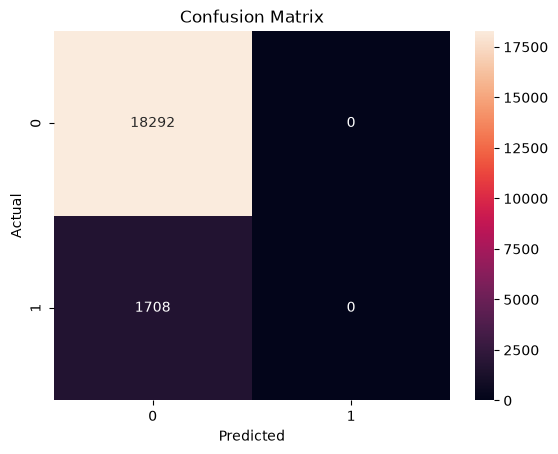

In [35]:
# Set the model to evaluation mode
# Switch the model to evaluation mode to disable dropout and batch normalization layers if present
# Disable gradient calculation to improve efficiency and reduce memory usage during inference, since gradients are not needed.
# Forward pass on test data: pass the standardized test tensor through the model to obtain predicted probabilities.
# Convert probabilities to binary predictions using a threshold of 0.5, then cast the boolean results to float type.
model.eval()  # Set the model to evaluation mode
with torch.no_grad():  # Disable gradient calculation for inference
    y_pred_prob = model(X_test_tensor)  # Forward pass on test data to get predicted probabilities
    y_pred = (y_pred_prob >= 0.5).float()  # Convert probabilities to binary predictions using threshold of 0.5

# Print classification report
# Print precision, recall, f1-score, and support for each class
y_test_labels = y_test_tensor.cpu().numpy().astype(int).ravel()
y_pred_labels = y_pred.cpu().numpy().astype(int).ravel()
print(classification_report(y_test_labels, y_pred_labels))

# Confusion matrix
# Compute the confusion matrix to evaluate classification performance
# Plot the confusion matrix as a heatmap with annotations
# Set the title of the plot
# Label the x-axis as 'Predicted'
# Label the y-axis as 'Actual'
# Display the plot
sns.heatmap(confusion_matrix(y_test_labels, y_pred_labels), annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [37]:
# Calculate model accuracy
# Count the number of correct predictions by comparing predicted and true labels, then sum and convert to Python integer

correct_predictions = (y_pred == y_test_tensor).sum().item()

# Get the total number of test samples by checking the size of the first dimension of the tensor
total_samples = y_test_tensor.size(0)

# Calculate the accuracy as the ratio of correct predictions to total samples
accuracy = correct_predictions / total_samples

# Output the computed test accuracy to the console
print(f"Test Accuracy: {accuracy:.4f}")

Test Accuracy: 0.9146
